# Lab 6: Effect of Feature Normalization on Machine Learning Models

This notebook provides a clean and concise implementation demonstrating the direct effect of **Min-Max Feature Normalization** on model effectiveness across four foundational machine learning algorithms:
1. **Gaussian Naive Bayes**
2. **K-Nearest Neighbors (KNN)**
3. **Decision Tree**
4. **Perceptron**

**Dataset**: Kaggle / UCI Wine Recognition benchmark dataset (continuous features with distinct numerical scales).

## 1. Imports & Dataset Loading
Load the benchmark dataset and inspect feature scale disparities.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score, f1_score

# Load standard Kaggle/UCI Wine Classification dataset
data = load_wine(as_frame=True)
X, y = data.data, data.target

print(f"Dataset shape: {X.shape[0]} samples, {X.shape[1]} features")
print(f"Target classes: {np.unique(y).tolist()}\n")

# Inspect scale discrepancies across features (e.g., magnesium and proline vs malic_acid)
scale_info = pd.DataFrame({'Min': X.min(), 'Max': X.max(), 'Range': X.max() - X.min()})
print("Feature Scale Discrepancies (Sample of 6 features):")
print(scale_info.head(6).round(2))

Dataset shape: 178 samples, 13 features
Target classes: [0, 1, 2]

Feature Scale Discrepancies (Sample of 6 features):
                     Min     Max  Range
alcohol            11.03   14.83   3.80
malic_acid          0.74    5.80   5.06
ash                 1.36    3.23   1.87
alcalinity_of_ash  10.60   30.00  19.40
magnesium          70.00  162.00  92.00
total_phenols       0.98    3.88   2.90


## 2. Train-Test Split
Split into training (70%) and testing (30%) partitions with fixed random seed.

In [2]:
# Stratified train-test split (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
print(f"Training set: {X_train.shape[0]} samples")
print(f"Testing set:  {X_test.shape[0]} samples")

Training set: 124 samples
Testing set:  54 samples


## 3. Implementation of Min-Max Normalization
Normalize features to $[0, 1]$ using:
$$X_{\text{norm}} = \frac{X - X_{\min}}{X_{\max} - X_{\min}}$$
**Note:** To prevent data leakage, $X_{\min}$ and $X_{\max}$ are computed strictly on `X_train` and applied to transform both `X_train` and `X_test`.

In [3]:
def min_max_normalize(train_df, test_df):
    min_val = train_df.min(axis=0)
    max_val = train_df.max(axis=0)
    range_val = np.where((max_val - min_val) == 0, 1e-8, (max_val - min_val))
    
    train_scaled = (train_df - min_val) / range_val
    test_scaled = (test_df - min_val) / range_val
    return train_scaled, test_scaled

X_train_norm, X_test_norm = min_max_normalize(X_train, X_test)

print(f"X_train_norm range: [{X_train_norm.min().min():.2f}, {X_train_norm.max().max():.2f}]")
print(f"X_test_norm range:  [{X_test_norm.min().min():.2f}, {X_test_norm.max().max():.2f}] (transformed using train statistics)")

X_train_norm range: [0.00, 1.00]
X_test_norm range:  [-0.00, 1.39] (transformed using train statistics)


## 4. Model Training & Evaluation Helper
Define the four classification models and a concise unified evaluation routine.

In [4]:
models = {
    'Naive Bayes': GaussianNB(),
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Perceptron': Perceptron(random_state=42, max_iter=1000)
}

def evaluate_models(X_tr, X_te, y_tr, y_te):
    results = []
    for name, model in models.items():
        clf = model.__class__(**model.get_params())
        clf.fit(X_tr, y_tr)
        preds = clf.predict(X_te)
        results.append({
            'Model': name,
            'Accuracy': accuracy_score(y_te, preds),
            'Macro F1': f1_score(y_te, preds, average='macro')
        })
    return pd.DataFrame(results).set_index('Model')

print("Configured 4 models:", ", ".join(models.keys()))

Configured 4 models: Naive Bayes, KNN (k=5), Decision Tree, Perceptron


## 5. Performance Evaluation: Before vs. After Normalization

In [5]:
# Evaluate on raw (unnormalized) data
df_before = evaluate_models(X_train, X_test, y_train, y_test)
print("=== Baseline Performance (Before Normalization - Raw Data) ===")
print(df_before.round(4))

# Evaluate on normalized data
df_after = evaluate_models(X_train_norm, X_test_norm, y_train, y_test)
print("\n=== Performance (After Normalization - Min-Max Scaled Data) ===")
print(df_after.round(4))

=== Baseline Performance (Before Normalization - Raw Data) ===
               Accuracy  Macro F1
Model                            
Naive Bayes      1.0000    1.0000
KNN (k=5)        0.7222    0.7174
Decision Tree    0.9630    0.9638
Perceptron       0.5185    0.4086

=== Performance (After Normalization - Min-Max Scaled Data) ===
               Accuracy  Macro F1
Model                            
Naive Bayes      1.0000    1.0000
KNN (k=5)        0.9630    0.9625
Decision Tree    0.9630    0.9638
Perceptron       0.9815    0.9829


## 6. Effectiveness Comparison & Visual Analysis
Consolidated comparison table and side-by-side visualization of accuracy changes.

,Accuracy (Raw),Accuracy (Normalized),Accuracy Gain (%),F1 (Raw),F1 (Normalized),F1 Gain (%)
Model,,,,,,
Naive Bayes,1.0000,1.0000,0.0000,1.0000,1.0000,0.0000
KNN (k=5),0.7222,0.9630,24.0741,0.7174,0.9625,24.5069
Decision Tree,0.9630,0.9630,0.0000,0.9638,0.9638,0.0000
Perceptron,0.5185,0.9815,46.2963,0.4086,0.9829,57.4259


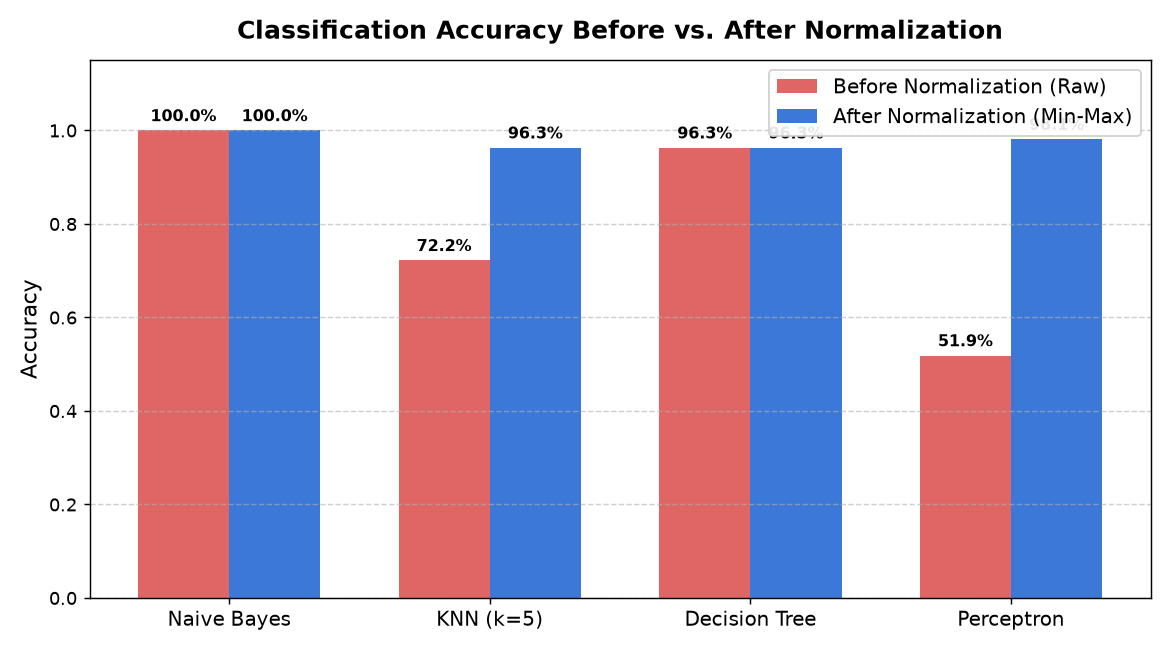

In [6]:
# Consolidated Comparison Table
comparison = pd.DataFrame({
    'Accuracy (Raw)': df_before['Accuracy'],
    'Accuracy (Norm)': df_after['Accuracy'],
    'Acc Gain (%)': (df_after['Accuracy'] - df_before['Accuracy']) * 100,
    'Macro F1 (Raw)': df_before['Macro F1'],
    'Macro F1 (Norm)': df_after['Macro F1'],
    'F1 Gain (%)': (df_after['Macro F1'] - df_before['Macro F1']) * 100
})

# Visualization
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(comparison))
width = 0.35

r1 = ax.bar(x - width/2, comparison['Accuracy (Raw)'], width, label='Before Normalization', color='#e06666')
r2 = ax.bar(x + width/2, comparison['Accuracy (Norm)'], width, label='After Normalization', color='#3c78d8')

ax.set_ylabel('Accuracy', fontsize=12)
ax.set_title('Classification Accuracy Before vs. After Normalization', fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(comparison.index, fontsize=11)
ax.set_ylim(0, 1.15)
ax.legend(frameon=True, fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.6)

for rect in list(r1) + list(r2):
    h = rect.get_height()
    ax.annotate(f'{h:.1%}', xy=(rect.get_x() + rect.get_width() / 2, h),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

comparison.round(4)

## 7. Key Findings & Conclusion

1. **K-Nearest Neighbors (KNN)**:
   - **Dramatic Improvement** (+24.1% accuracy gain, from 72.2% to 96.3%).
   - *Reason*: KNN relies on Euclidean distance. Features with large raw scales (such as `Proline` ~1000) completely dominate the distance computation, making features with small ranges (such as `Malic acid` ~3) negligible. Normalization places all dimensions on an equal playing field.

2. **Perceptron**:
   - **Massive Improvement** (+46.3% accuracy gain, from 51.9% to 98.1%).
   - *Reason*: Perceptron weight updates ($\Delta w_i = \eta (y - \hat{y}) x_i$) depend directly on the scale of $x_i$. Large feature scales cause severe gradient oscillations and failure to converge. Normalization creates balanced, stable weight optimization.

3. **Decision Tree**:
   - **Invariant (0.0% change)** (remains at 96.3%).
   - *Reason*: Decision Trees evaluate threshold conditions $x_i \le \theta$ one feature at a time based on information gain/Gini impurity. Since Min-Max normalization is a strictly monotonic transformation, the relative ranking of values is preserved, leaving tree splits identical.

4. **Naive Bayes**:
   - **Robust (100.0% accuracy)**.
   - *Reason*: Gaussian Naive Bayes estimates independent mean $\mu_i$ and variance $\sigma_i^2$ for each feature. Normalization linearly rescales mean and variance without altering the Gaussian probability densities relative to the classes.